In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import os
import sys
import glob
import uproot

def gaus(x, A, mean, std):
    return A * np.exp(-1 * (x - mean)**2 / 2*(std))

def sigmoid(x, A, mean, width):
    return (A / (1 + np.exp(-1 * width * (x - mean))))

proc_F_AC_LGAD_40um_strip_10db_attenuation_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos42.4_Xpos41.075_Ypos104.200000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos42.4_Xpos41.150000000000006_Ypos104.200000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos42.4_Xpos40.875_Ypos104.200000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos42.4_Xpos41.0_Ypos104.200000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos42.4_Xpos41.1_Ypos104.200000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos42.4_Xpos40.75_Ypos104.200000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos42.4_Xpos41.050000000000004_Ypos104.200000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos42.4_Xpos40.95_Ypos104.200000.root
proc_F_AC_LGAD_40um_strip_10db

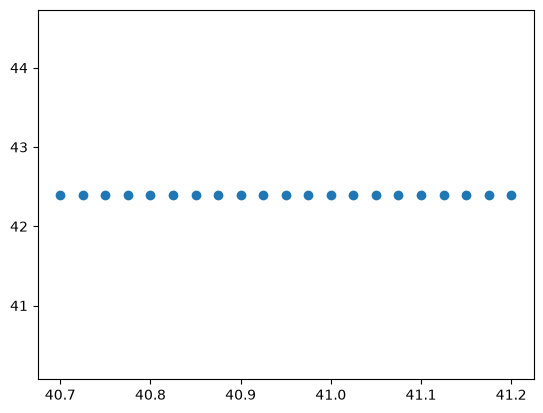

In [2]:
path = "../../Processed_data/"
# path = "../../ZAxisScan/"
# files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.root")
files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_10db_attenuation_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos*_Xpos*_Ypos*00000.root")

# files = glob.glob(f"{path}F*--AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.trc")

Z_range = [] # np.linspace(50.0, 50.8, 11)
X_range = [] # np.linspace(41.4, 41.7, 21)
Y_range = []

map_plot_x = []
map_plot_y = []
map_plot_z = []

for file in files:
    filename = file.split(path)[1]
    print(filename)
    x_pos = float(filename.split("Xpos")[1].split("_")[0])
    y_pos = float(filename.split("Ypos")[1].split("00000.root")[0])
    z_pos = float(filename.split("Zpos")[1].split("_")[0])
    map_plot_x.append(x_pos)
    map_plot_y.append(y_pos)
    map_plot_z.append(z_pos)
    X_range.append(x_pos)
    Y_range.append(y_pos)
    Z_range.append(z_pos)

Z_range = np.unique(Z_range)
X_range = np.unique(X_range)
Y_range = np.unique(Y_range)

# map_plot_x = np.sort(map_plot_x)
# map_plot_z = np.sort(map_plot_z)

plt.scatter(map_plot_x, map_plot_z)
plt.show()

fields = [
    'i_evt',
    # 'channel',
    # 'time',
    # 'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    # 't_peak',
    'integral',
    # 'intfull',
    # 'risetime',
    # 'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]
    

# Read and store specific branches.

In [3]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}
risetime = {}
channel = {}
time = {}

for f_i, f in enumerate(files):
    pulse = uproot.open(f)["pulse"].arrays(fields)
    l = f"pos_{map_plot_z[f_i]}_{map_plot_x[f_i]}_{map_plot_y[f_i]}"
    # channel[l] = pulse["channel"]
    # time[l] = pulse["time"]
    integral[l] = pulse["integral"]
    # risetime[l] = pulse["risetime"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]
    del pulse

print(amp.keys())

dict_keys(['pos_42.4_41.075_104.2', 'pos_42.4_41.150000000000006_104.2', 'pos_42.4_40.875_104.2', 'pos_42.4_41.0_104.2', 'pos_42.4_41.1_104.2', 'pos_42.4_40.75_104.2', 'pos_42.4_41.050000000000004_104.2', 'pos_42.4_40.95_104.2', 'pos_42.4_41.125_104.2', 'pos_42.4_40.725_104.2', 'pos_42.4_40.975_104.2', 'pos_42.4_40.85_104.2', 'pos_42.4_41.025000000000006_104.2', 'pos_42.4_40.825_104.2', 'pos_42.4_40.925000000000004_104.2', 'pos_42.4_40.775000000000006_104.2', 'pos_42.4_41.175000000000004_104.2', 'pos_42.4_40.7_104.2', 'pos_42.4_40.800000000000004_104.2', 'pos_42.4_41.2_104.2', 'pos_42.4_40.900000000000006_104.2'])


## Amplitude and NEvents vs z position.

In [ ]:
cols = 2
rows = 1
size = 7

fig, ax = plt.subplots(rows, cols, figsize = (size*cols, size*rows))
# Z_range = [50.0, 50.8]
for z_i, z in enumerate(Z_range):
    mean_amps = []
    n_events = []
    for x_i, x in enumerate(X_range):
        # if x < 40.8: continue
        if x < 0: continue
        for y_i, y in enumerate(Y_range):
            # l = f"pos_{map_plot_z[z_i]}_{map_plot_x[x_i]}"
            l = f"pos_{z}_{x}_{y}"
            # mean_amps.append(np.mean(amp[l][:,0]))
            # n_events.append(np.sum(timestamps[l][:,0]>0))
            try:
                # print(z, x)
                mean_amps.append(np.mean(amp[l][:,0]))
                n_events.append(np.sum(timestamps[l][:,0]>0))
                # print(l, mean_amps[-1]) # , n_events[-1])
            except:
                # print(f"{l} is not ready or taken yet")
                mean_amps.append(0)
                n_events.append(0)
    
    sorting = np.argsort(X_range)
    mean_amps = np.array(mean_amps)
    n_events = np.array(n_events)

    # print(X_range[mean_amps != 0])
    # print(mean_amps[mean_amps != 0])
    mask = (mean_amps != 0) & (mean_amps > 41.8) & (mean_amps < 41.0)
    params = curve_fit(gaus, X_range[X_mask][mask], mean_amps[mask], p0 = (np.max(mean_amps[mask]), np.mean(X_range), 10))

    X_mask = (X_range >= 0) # (X_range >= 40.8) # & (X_range < 40.86)
    ax[0].plot(X_range[X_mask], mean_amps, label = f"Z position: {z}", marker = "o")
    gaussian = [gaus(i, params[0][0], params[0][1], params[0][2]) for i in X_range[X_mask]]
    ax[0].plot(X_range[X_mask], gaussian, label = f"Z position: {z}, params: {np.round(params[0][0], 3)}, {np.round(params[0][1], 3)}, {np.round(params[0][2], 3)}")
    ax[0].set_xlabel("X position [mm]")
    ax[0].set_ylabel("Mean amplitude")
    # ax[0].set_ylim(5, 30)
    # ax[0].set_xlim(40.7, 40.9)

    # try:
    mask = (mean_amps != 0) #  & (mean_amps > 41.4) & (mean_amps < 41.7)
    print(np.sum(mask))
    if (np.sum(mask) == 0): continue
    # params = curve_fit(sigmoid, X_range[X_mask][mask], mean_amps[mask], p0 = (np.max(mean_amps[mask]), np.mean(X_range), 10))
    # sigmoid_y = [sigmoid(i, params[0][0], params[0][1], params[0][2]) for i in X_range[X_mask]]
    # print(sigmoid_y)
    # ax[0].plot(X_range[X_mask], sigmoid_y, label = f"Z position: {z}, sigmoid params: {np.round(params[0][0], 3)}, {np.round(params[0][1], 3)}, {np.round(params[0][2], 3)}")
    ax[0].legend()

    ax[1].plot(X_range[X_mask], n_events, label = f"Z position: {z}")
    ax[1].set_xlabel("X position [mm]")
    ax[1].set_ylabel("Number of events")

    plt.legend()
plt.show()

[]
[]


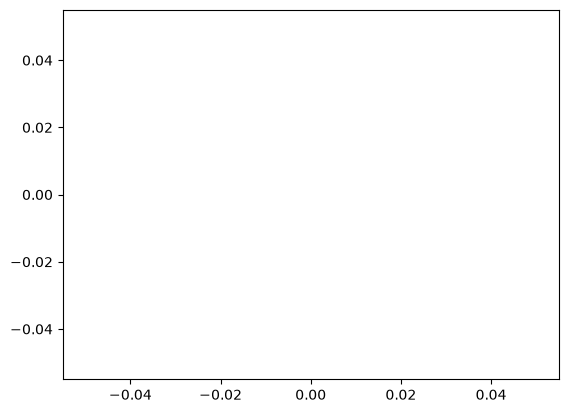

In [6]:
x_range = []
n_events = []
amp_means = []

for i in timestamps.keys():
    z = float(i.split("_")[1])
    if (z == 50.56):
        x = float(i.split("pos_")[1].split("_")[1])
        x_range.append(x)
        amp_means.append(np.mean(amp[i][:,0]))
        
        print(i, np.mean(amp[i][:,0]))
        print()

sort_condition = np.argsort(x_range)

x_range = np.array(x_range)[sort_condition]
amp_means = np.array(amp_means)[sort_condition]

print(x_range)
print(amp_means)

plt.plot(x_range, amp_means)
plt.show()